# WP4: Invariant manifolds and application to Mars exploration mission

## Personal problem specification 

| Parameter | Value |
|-----------|-------|
| Sun/Earth Lagrange point | L2 |
| Sun/Mars Lagrange point | L2 |
| Shift in Lagrange points | 0.00100 |
| Radius Martian parking orbit | 244,444 km |
| Lightness number | 0.0300 |

## Library & constant imports

In [51]:
from constants import *

import numpy as np
import scipy 
from scipy.integrate import solve_ivp
from scipy.optimize import newton
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import pickle
import nbimporter
from IPython.display import display

from auxiliary_functions import *

# ── Font sizes for plots (adjustable) ──────────────────────────────────────────
FONTSIZE_SMALL = 16              # Contour labels, small text
FONTSIZE_TICKS = 15              # Tick labels
FONTSIZE_AXIS_LABELS = 30        # Axis point labels
FONTSIZE_XLABEL_YLABEL = 16      # Axis label text
FONTSIZE_LEGEND = 15             # Legend and annotations
FONTSIZE_TITLE = 36              # Main titles

Importing of the eigenvalues and eigenvectors saved from the notebook for WP3. 

In [52]:
with open('eigenvalues_eigenvectors.pkl', 'rb') as f:
    eigenvalues_eigenvectors = pickle.load(f)

eigenvalues_mars_classical = eigenvalues_eigenvectors['eigenvalues_mars_classical']
eigenvectors_mars_classical = eigenvalues_eigenvectors['eigenvectors_mars_classical']

And also importing the Lagrange points position.

In [53]:
with open('lagrange_points.pkl', 'rb') as f:
    lagrange_points = pickle.load(f)

# L2_earth = lagrange_points['L2_earth']
L2_mars  = lagrange_points['L2_mars']

## Task 4.1

Computing and plotting the unstable and stable manifolds for the **classical Sun-Mars Lagrange point**, using the following parameters provided in the assignment text. 

In [54]:
earth_years = 5
tolerance = 1e-12 # absolute and relative integration tolerance
perturbation_magnitude = 1e-5 

time_span = earth_years * year_in_seconds / time_unit_sun_mars
time_span

19.11773909684742

It implies the integration of the stable and unstable equations of motion. First, the unstable one will be considered. 

### Unstable manifold

In [55]:
unstable_eigenvalue_mars = eigenvalues_mars_classical[0].real
unstable_eigenvector_mars = eigenvectors_mars_classical[:, 0].real 
print("Unstable eigenvalue:", unstable_eigenvalue_mars)
print("Unstable eigenvector:", unstable_eigenvector_mars)

Unstable eigenvalue: 2.4969462455360953
Unstable eigenvector: [-0.32680059  0.17726628 -0.8160035   0.44262437]


Once checked that the values are the one corresponding to the unstable manifold (eigenvalue with positive real part), the EOM are integrated.

In [56]:
state0_unstable_plus = np.array([L2_mars, 0.0, 0.0, 0.0]) + perturbation_magnitude * unstable_eigenvector_mars
state0_unstable_minus = np.array([L2_mars, 0.0, 0.0, 0.0]) - perturbation_magnitude * unstable_eigenvector_mars

sol_unstable_plus = solve_ivp(eom, [0, time_span], state0_unstable_plus, args=(mass_ratio_sun_mars,), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)
sol_unstable_minus = solve_ivp(eom, [0, time_span], state0_unstable_minus, args=(mass_ratio_sun_mars,), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)

### Stable manifold

In [57]:
stable_eigenvalue_mars = eigenvalues_mars_classical[1].real
stable_eigenvector_mars = eigenvectors_mars_classical[:, 1].real 
print("Stable eigenvalue:", stable_eigenvalue_mars)
print("Stable eigenvector:", stable_eigenvector_mars)

Stable eigenvalue: -2.496946245536095
Stable eigenvector: [-0.32680059 -0.17726628  0.8160035   0.44262437]


Once checked that the values are the one corresponding to the stable manifold (eigenvalue with negative real part), the EOM are integrated. Mind that the integration interval now goes from $[0, -t]$ (the opposite as before). 

In [58]:
state0_stable_plus = np.array([L2_mars, 0.0, 0.0, 0.0]) + perturbation_magnitude * stable_eigenvector_mars
state0_stable_minus = np.array([L2_mars, 0.0, 0.0, 0.0]) - perturbation_magnitude * stable_eigenvector_mars

sol_stable_plus = solve_ivp(eom, [0, -time_span], state0_stable_plus, args=(mass_ratio_sun_mars,), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)
sol_stable_minus = solve_ivp(eom, [0, -time_span], state0_stable_minus, args=(mass_ratio_sun_mars,), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)

### Plotting the results

For the plotting, the Mars parking orbit also has to be computed

In [59]:
radius_parking = radius_mars_parking_orbit / length_unit_sun_mars

Also the dimensionless distance of the Earth's orbit in the Sun-Mars system:

In [60]:
distance_earth = AU / length_unit_sun_mars
theta = np.linspace(0, 2 * np.pi, 100)
earth_orbit = distance_earth * np.array([[np.cos(t)-mass_ratio_sun_mars, np.sin(t)] for t in theta]) # the subtration to center it around the sun

Coupling the trajectories for plotting

In [61]:
t_unstable_coupled = np.concatenate([-sol_unstable_minus.t[::-1], sol_unstable_plus.t])
y_unstable_coupled = np.concatenate([sol_unstable_minus.y[:, ::-1], sol_unstable_plus.y], axis=1)

t_stable_coupled = np.concatenate([-sol_stable_minus.t[::-1], sol_stable_plus.t])
y_stable_coupled = np.concatenate([sol_stable_minus.y[:, ::-1], sol_stable_plus.y], axis=1)

System-wide view of the manifolds:

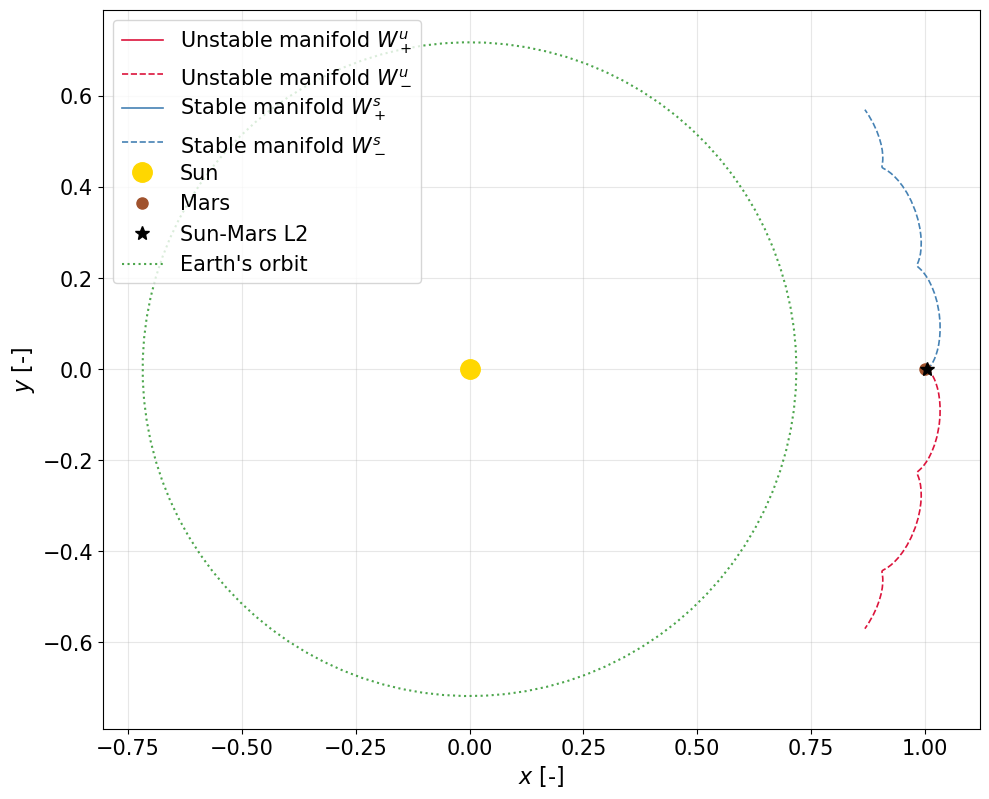

In [62]:
# ── System-wide view ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 10))

# Mars position in the rotating frame (at x = 1 - mu, y = 0)
x_mars = 1 - mass_ratio_sun_mars

# Manifold trajectories
ax.plot(sol_unstable_plus.y[0], sol_unstable_plus.y[1],
        color='crimson', lw=1.2, label='Unstable manifold $W^u_+$')
ax.plot(sol_unstable_minus.y[0], sol_unstable_minus.y[1],
        color='crimson', lw=1.2, ls='--', label='Unstable manifold $W^u_-$')
ax.plot(sol_stable_plus.y[0], sol_stable_plus.y[1],
        color='steelblue', lw=1.2, label='Stable manifold $W^s_+$')
ax.plot(sol_stable_minus.y[0], sol_stable_minus.y[1],
        color='steelblue', lw=1.2, ls='--', label='Stable manifold $W^s_-$')

# Sun (at x = -mu, y = 0) and Mars markers
ax.plot(-mass_ratio_sun_mars, 0, 'o', color='gold', ms=14, zorder=5, label='Sun')
ax.plot(x_mars, 0, 'o', color='sienna', ms=8, zorder=5, label='Mars')

# L2 marker
ax.plot(L2_mars, 0, '*', color='black', ms=10, zorder=5, label=f'Sun-Mars L2')

# Earth's orbit
ax.plot(earth_orbit[:, 0], earth_orbit[:, 1], color='green', lw=1.5, ls=':', alpha=0.7, label="Earth's orbit")

ax.set_xlabel(r'$x$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax.set_ylabel(r'$y$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
# ax.set_title('System-wide view — Sun-Mars invariant manifolds', fontsize=FONTSIZE_SMALL)
ax.set_aspect('equal')
ax.tick_params(labelsize=FONTSIZE_TICKS)
ax.legend(fontsize=FONTSIZE_LEGEND, loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/wp4_manifolds_system_wide.pdf', dpi=150, bbox_inches='tight')
plt.show()

Close-up view of the projections of the manifolds: 

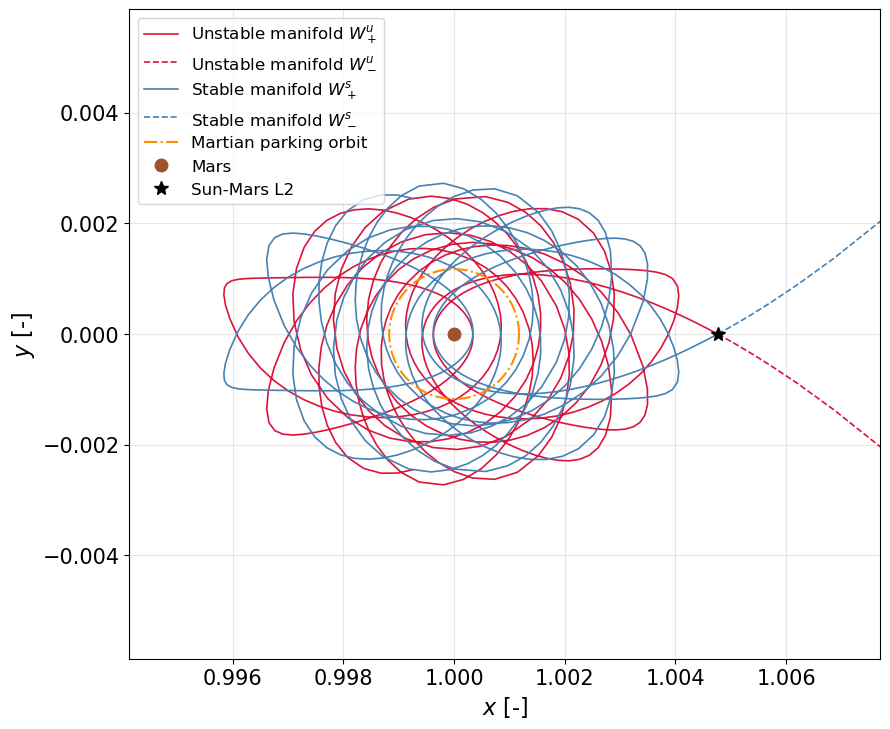

In [63]:
# ── Close-up view near Mars ───────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 9))

x_mars = 1 - mass_ratio_sun_mars

# Manifold trajectories
ax.plot(sol_unstable_plus.y[0], sol_unstable_plus.y[1],
        color='crimson', lw=1.2, label='Unstable manifold $W^u_+$')
ax.plot(sol_unstable_minus.y[0], sol_unstable_minus.y[1],
        color='crimson', lw=1.2, ls='--', label='Unstable manifold $W^u_-$')
ax.plot(sol_stable_plus.y[0], sol_stable_plus.y[1],
        color='steelblue', lw=1.2, label='Stable manifold $W^s_+$')
ax.plot(sol_stable_minus.y[0], sol_stable_minus.y[1],
        color='steelblue', lw=1.2, ls='--', label='Stable manifold $W^s_-$')
        
# Martian parking orbit (circle of radius radius_parking centred on Mars)
theta = np.linspace(0, 2 * np.pi, 1000)
ax.plot(x_mars + radius_parking * np.cos(theta),
        radius_parking * np.sin(theta),
        color='darkorange', lw=1.5, ls='-.', label='Martian parking orbit')

# Mars and L2 markers
ax.plot(x_mars, 0, 'o', color='sienna', ms=9, zorder=5, label='Mars')
ax.plot(L2_mars, 0, '*', color='black', ms=10, zorder=5, label='Sun-Mars L2')

# Set axis limits centred on Mars with some margin
margin = 5 * radius_parking
ax.set_xlim(x_mars - margin, L2_mars + margin * 0.5)
ax.set_ylim(-margin, margin)

ax.set_xlabel(r'$x$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax.set_ylabel(r'$y$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
# ax.set_title('Close-up view — manifold structure near Mars', fontsize=FONTSIZE_SMALL)
ax.set_aspect('equal')
ax.tick_params(labelsize=FONTSIZE_TICKS)
ax.legend(fontsize=FONTSIZE_LEGEND-3, loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/wp4_manifolds_closeup.pdf', dpi=150, bbox_inches='tight')
plt.show()

## Task 4.2b 

To compute the $\Delta V$ for the required transfer, it will be assessed among all the intersection points. Notably, because the transfer happens from the manifold to the orbit, only the unstable manifold needs to be evaluated. Because the output of the integrator is a dense one, the solution can be iterated to find the exact crossing times.

In [64]:
def find_orbit_crossings(sol, center_x=1-mass_ratio_sun_mars, center_y=0, radius=radius_parking):
    """Find times and states when trajectory crosses a circular orbit."""
    t_eval = np.linspace(sol.t[0], sol.t[-1], len(sol.t))
    pos = sol.sol(t_eval)[:2]
    
    dist_error = np.sqrt((pos[0] - center_x)**2 + (pos[1] - center_y)**2) - radius
    crossing_idx = np.where(np.diff(np.sign(dist_error)))[0]
    
    crossing_times, crossing_states = [], []
    
    for idx in crossing_idx:
        def dist_func(t):
            s = sol.sol(t)
            return np.sqrt((s[0] - center_x)**2 + (s[1] - center_y)**2) - radius
        
        t_cross = newton(dist_func, (t_eval[idx] + t_eval[idx + 1]) / 2)
        crossing_times.append(t_cross)
        crossing_states.append(sol.sol(t_cross))
    
    return np.array(crossing_times), np.array(crossing_states)

Find crossings for unstable manifold:

In [65]:
t_cross_unstable_plus, states_cross_unstable_plus = find_orbit_crossings(sol_unstable_plus)
t_cross_unstable_minus, states_cross_unstable_minus = find_orbit_crossings(sol_unstable_minus)

print(f"Unstable+ crossings: {len(t_cross_unstable_plus)} at times {t_cross_unstable_plus}.")
print(f"Unstable- crossings: {len(t_cross_unstable_minus)} at times {t_cross_unstable_minus}.")

Unstable+ crossings: 10 at times [ 2.68699762  2.80475355  6.39101456  6.49651966  8.50697533  8.62366617
 13.57353563 13.68868573 15.58598586 15.69401422].
Unstable- crossings: 0 at times [].


We only need to consider the positive branch. Computing the required velocity vector at each point. 
$$v_{circ} = \sqrt{\frac{\mu_{\text{Mars}}}{R_{\text{parking}}}}$$
From now onwards (in this task) the magnides are dimensional. 

In [66]:
velocity_parking = np.sqrt(mu_mars / radius_mars_parking_orbit) * 1e3

Conversion of the crossing states to dimensional units:

In [67]:
states_cross_unstable_plus[:, 0:2] -= np.array([1 - mass_ratio_sun_mars, 0.0]) # to shift th ecenter
position_cross = states_cross_unstable_plus[:, 0:2]*length_unit_sun_mars # km
velocity_cross = states_cross_unstable_plus[:, 2:4]*length_unit_sun_mars / time_unit_sun_mars * 1e3 # m/s
# position_cross, velocity_cross, velocity_parking
# position_cross[:, 0]

Now, we calculate the direction that the velocity vector needs to have in each of the crossing points (tangential to the orbit). After that, the vector is scaled to have the magnitude of the proper velocity vector. 

In [68]:
velocity_orientation_orbit = np.arctan2(position_cross[:, 1], position_cross[:, 0])
v_orbit_unit = np.column_stack([np.cos(velocity_orientation_orbit), np.sin(velocity_orientation_orbit)]) # [-]
v_orbit = velocity_parking * v_orbit_unit  # m/s
# np.linalg.norm(v_orbit, axis=1)

And, finally, the required $\Delta V$ is computed. The value taken is the minimum of the possible during the integration window. 

In [69]:
deltaV_m = np.linalg.norm(v_orbit - velocity_cross, axis=1)
print(f"DeltaV for Mars insertion (m/s): {deltaV_m}")
idx_min = np.argmin(deltaV_m)
minimum_deltaV = deltaV_m[idx_min]
print(f"Minimum DeltaV for Mars insertion (m/s): {minimum_deltaV:.3f}")
t_insertion = t_cross_unstable_plus[idx_min] * time_unit_sun_mars / year_in_seconds
print(f"Time of minimum DeltaV insertion: {t_insertion:.5f} Earth years.")

DeltaV for Mars insertion (m/s): [813.42707545 361.96290574 846.65549509 276.3580295  763.22354114
 457.08989028 759.70999354 466.06249076 841.87877251 291.53129325]
Minimum DeltaV for Mars insertion (m/s): 276.358
Time of minimum DeltaV insertion: 1.69908 Earth years.


### Plot of the maneuver up to the transfer 

Similar close-up view as before. 

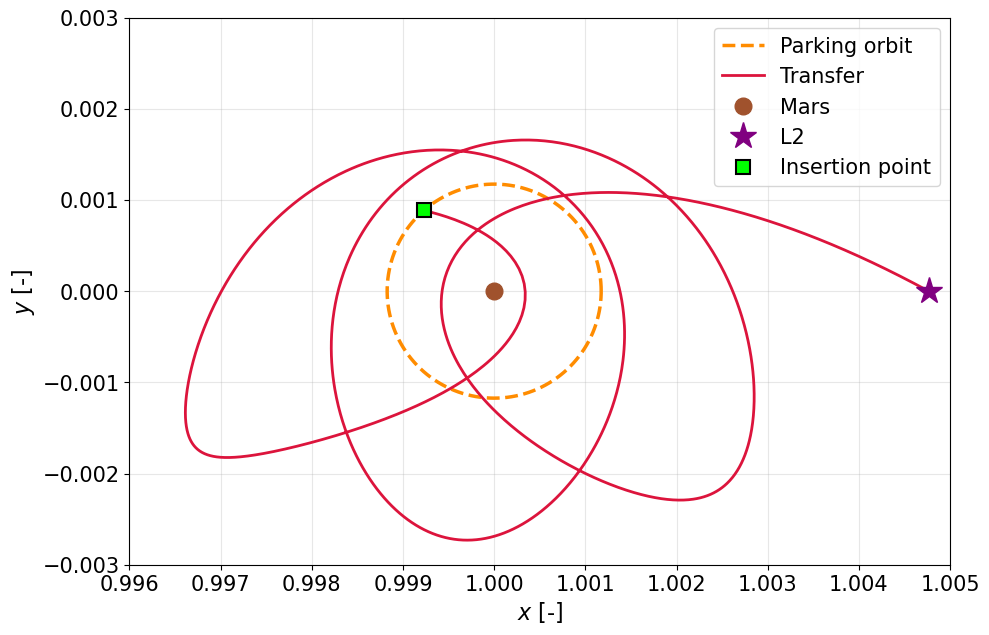

In [70]:
fig, ax = plt.subplots(figsize=(10, 10))

t_intersection = t_cross_unstable_plus[idx_min]

t_transfer = np.linspace(0, t_intersection, 3000)
traj_transfer = sol_unstable_plus.sol(t_transfer)

theta = np.linspace(0, 2*np.pi, 300)
parking_orbit_x = x_mars + radius_parking * np.cos(theta)
parking_orbit_y = radius_parking * np.sin(theta)

intersection_x = states_cross_unstable_plus[idx_min, 0] + x_mars
intersection_y = states_cross_unstable_plus[idx_min, 1]

ax.plot(parking_orbit_x, parking_orbit_y, color='darkorange', lw=2.5, 
        ls='--', label='Parking orbit', zorder=2)
ax.plot(traj_transfer[0], traj_transfer[1], color='crimson', lw=2.0, 
        label='Transfer', zorder=3)
ax.plot(x_mars, 0, 'o', color='sienna', ms=12, label='Mars', zorder=4)
ax.plot(L2_mars, 0.0, '*', color='purple', ms=20, 
        label='L2', zorder=5)
ax.plot(intersection_x, intersection_y, 's', color='lime', ms=10, 
        label='Insertion point', zorder=6, markeredgecolor='black', markeredgewidth=1.5)

ax.set_xlim(0.996, 1.005)
ax.set_ylim(-0.003, 0.003)
ax.set_xlabel(r'$x$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax.set_ylabel(r'$y$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
# ax.set_title('Transfer from L2 to Mars Parking Orbit', fontsize=FONTSIZE_TITLE)
ax.set_aspect('equal')
ax.tick_params(labelsize=FONTSIZE_TICKS)
ax.legend(fontsize=FONTSIZE_LEGEND, loc='best')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/wp4_transfer_closeup.pdf', dpi=150, bbox_inches='tight')
plt.show()

## Task 4.3

Now, we need to use the ideal solar-sail acceleration model for propagating the EOM. For the personal problem specification (L2), the following legs need to be computed:

1. **Earth -> L2**: Stable right (adding a positive perturbation along the eigenvector: stable plus)
2. **L2 -> Mars parking orbit**: Unstable left (adding a negative perturbation along the eigenvector: unstable minus)

In [71]:
cone_angles = np.linspace(-90, 90, 73) # hardcoding the 2.5 diff
cone_angles_rad = np.radians(cone_angles)

beta_problem = lightness_number

### Earth to L2 transfer

In [72]:
for alpha in cone_angles_rad:
    sol_solar_sail = solve_ivp(eom, [0, -time_span], state0_unstable_plus, args=(mass_ratio_sun_mars, beta_problem, alpha), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)
    t_cross_solar_sail, states_cross_solar_sail = find_orbit_crossings(sol_solar_sail, center_x=-mass_ratio_sun_mars, center_y=0, radius=distance_earth)
    if len(t_cross_solar_sail) > 0:
        print(f"Alpha: {np.degrees(alpha):.1f} deg, 1st crossing time: {t_cross_solar_sail[0] * time_unit_sun_mars / year_in_seconds:.5f} years. Total crossings: {len(t_cross_solar_sail)}.")
    # else:
        # print(f"Alpha (degrees): {np.degrees(alpha):.1f}, No crossings found.")

Alpha: -55.0 deg, 1st crossing time: -4.85767 years. Total crossings: 1.
Alpha: -52.5 deg, 1st crossing time: -4.51527 years. Total crossings: 1.
Alpha: -50.0 deg, 1st crossing time: -3.91349 years. Total crossings: 1.
Alpha: -47.5 deg, 1st crossing time: -3.75031 years. Total crossings: 1.
Alpha: -45.0 deg, 1st crossing time: -3.64064 years. Total crossings: 1.
Alpha: -42.5 deg, 1st crossing time: -3.56497 years. Total crossings: 1.
Alpha: -40.0 deg, 1st crossing time: -3.51731 years. Total crossings: 1.
Alpha: -37.5 deg, 1st crossing time: -3.49554 years. Total crossings: 1.
Alpha: -35.0 deg, 1st crossing time: -3.49891 years. Total crossings: 1.
Alpha: -32.5 deg, 1st crossing time: -3.52697 years. Total crossings: 1.
Alpha: -30.0 deg, 1st crossing time: -3.57931 years. Total crossings: 1.
Alpha: -27.5 deg, 1st crossing time: -3.65612 years. Total crossings: 1.
Alpha: -25.0 deg, 1st crossing time: -3.75928 years. Total crossings: 1.
Alpha: -22.5 deg, 1st crossing time: -3.89510 years

### L2 to Mars parking orbit transfer

In [73]:
for alpha in cone_angles_rad:
    sol_solar_sail = solve_ivp(eom, [0, time_span], state0_stable_minus, args=(mass_ratio_sun_mars, beta_problem, alpha), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)
    t_cross_solar_sail, states_cross_solar_sail = find_orbit_crossings(sol_solar_sail)
    if len(t_cross_solar_sail) > 0:
        print(f"Alpha: {np.degrees(alpha):.1f} deg, 1st crossing time: {t_cross_solar_sail[0] * time_unit_sun_mars / year_in_seconds:.5f} years. Total crossings: {len(t_cross_solar_sail)}.")
    # else:
        # print(f"Alpha (degrees): {np.degrees(alpha):.1f}, No crossings found.")

Alpha: -90.0 deg, 1st crossing time: 1.14571 years. Total crossings: 10.
Alpha: 67.5 deg, 1st crossing time: 0.67318 years. Total crossings: 4.
Alpha: 70.0 deg, 1st crossing time: 0.49823 years. Total crossings: 6.
Alpha: 72.5 deg, 1st crossing time: 0.46606 years. Total crossings: 10.
Alpha: 75.0 deg, 1st crossing time: 0.46230 years. Total crossings: 10.
Alpha: 77.5 deg, 1st crossing time: 0.47533 years. Total crossings: 20.
Alpha: 80.0 deg, 1st crossing time: 0.50331 years. Total crossings: 20.
Alpha: 82.5 deg, 1st crossing time: 0.54890 years. Total crossings: 14.
Alpha: 85.0 deg, 1st crossing time: 0.62152 years. Total crossings: 10.
Alpha: 87.5 deg, 1st crossing time: 0.75441 years. Total crossings: 10.
Alpha: 90.0 deg, 1st crossing time: 1.14571 years. Total crossings: 10.
